# 1. Introduction & Setup

### 1.1 Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

ORDER = ["Success", "At Risk", "Failure"]
PALETTE = {"Success": "#2e7d32", "At Risk": "#f9a825", "Failure": "#c62828"}

### 1.2 Loading the Dataset

In [3]:
file_name = "smart_rocket_Data.xlsx"
train_df = pd.read_excel(file_name, sheet_name="Training Data")
test_df = pd.read_excel(file_name, sheet_name="Challenge Data").iloc[:, :7]

cols = ["Engine Temp (°C)", "Speed (km/h)", "Altitude (km)",
        "Pressure (kPa)", "Fuel Remaining (%)", "Trajectory Deviation (°)"]
short = {c: c.split(" (")[0] for c in cols}       # short names for the reasoning text
print(train_df.shape, test_df.shape)

(50, 8) (15, 7)


# 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset Understanding

In [4]:
print("--- Training Data Info ---")
train_df.info()

print("\n--- Training Data Describe ---")
display(train_df.describe().round(2))

print(train_df["Result"].value_counts())
print("\n--- missing value ---")
train_df.isna().sum().sum()

--- Training Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Flight ID                 50 non-null     object 
 1   Engine Temp (°C)          50 non-null     float64
 2   Speed (km/h)              50 non-null     float64
 3   Altitude (km)             50 non-null     float64
 4   Pressure (kPa)            50 non-null     float64
 5   Fuel Remaining (%)        50 non-null     float64
 6   Trajectory Deviation (°)  50 non-null     float64
 7   Result                    50 non-null     object 
dtypes: float64(6), object(2)
memory usage: 3.3+ KB

--- Training Data Describe ---


,Engine Temp (°C),Speed (km/h),Altitude (km),Pressure (kPa),Fuel Remaining (%),Trajectory Deviation (°)
count,50.00,50.00,50.00,50.00,50.00,50.00
mean,737.59,804.89,19.28,78.79,57.06,4.07
std,90.16,162.91,6.20,15.69,20.25,2.16
min,582.40,514.80,7.80,55.50,25.50,0.40
25%,674.50,648.85,14.65,66.43,41.70,2.20
50%,724.65,807.35,19.30,74.80,54.60,3.80
75%,794.98,949.95,24.65,92.98,77.25,5.85
max,905.50,1049.00,29.40,104.90,93.90,7.50


Result
Success    21
At Risk    16
Failure    13
Name: count, dtype: int64

--- missing value ---


np.int64(0)

### 2.2 Data Visualization

,Engine Temp (°C),Speed (km/h),Altitude (km),Pressure (kPa),Fuel Remaining (%),Trajectory Deviation (°)
Result,,,,,,
Success,700.6,861.7,22.1,84.8,67.1,3.2
At Risk,764.2,814.2,18.7,76.9,50.9,4.0
Failure,764.6,701.7,15.4,71.5,48.5,5.5


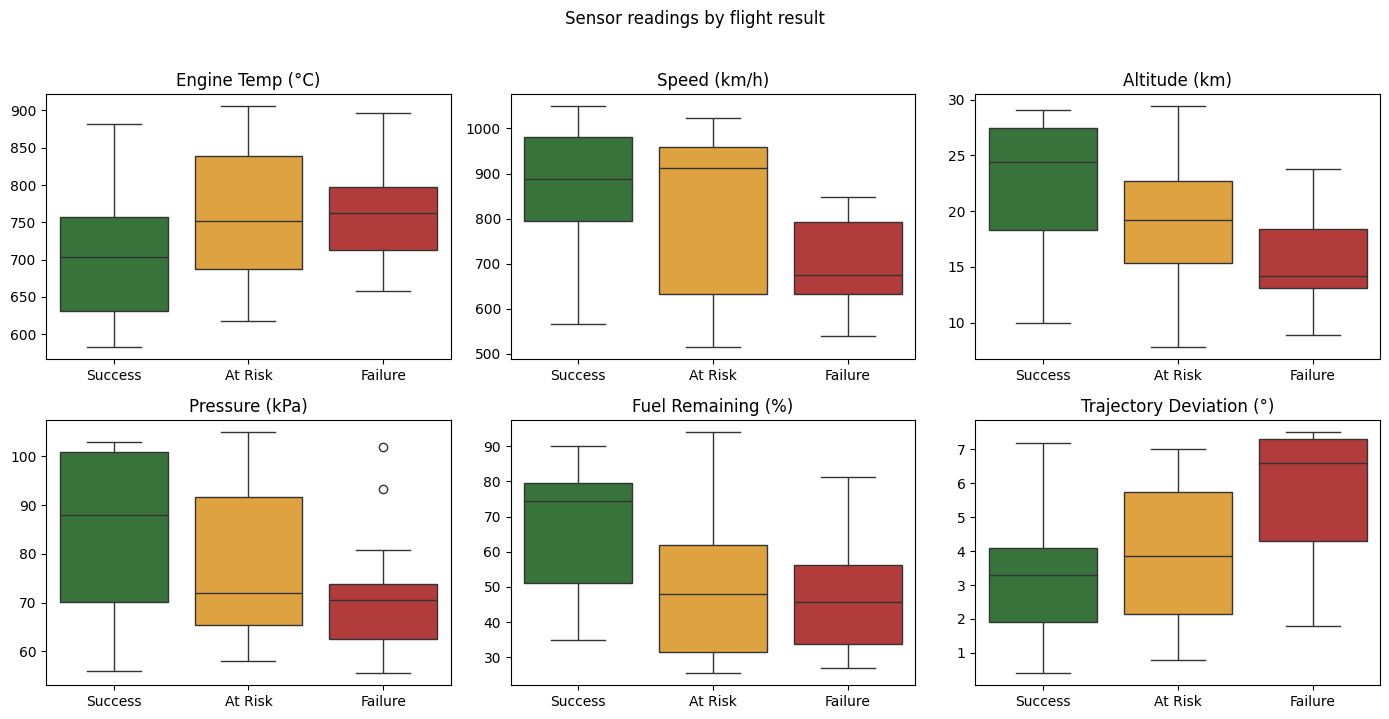

In [5]:
display(train_df.groupby("Result")[cols].mean().loc[ORDER].round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=train_df, x="Result", y=c, order=ORDER, hue="Result",
                palette=PALETTE, legend=False, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Sensor readings by flight result", y=1.02); plt.tight_layout(); plt.show()

**successful** flights have lower engine temperature and trajectory deviation, and higher speed, altitude, pressure and fuel. **Failures** show the opposite, and **At Risk** sits in between.
No single reading separates the classes on its own, so all six contribute.

# 3. Building the Model

### 3.1 Feature Engineering: Health Score
Combine all six readings into one score, since all six showed a clear pattern.

In [6]:
directions = pd.Series([-1, 1, 1, 1, 1, -1], index=cols)

def health_points(df, ref):
    """Per-reading points (positive helps success, negative hurts), standardized with `ref` statistics."""
    return (df[cols] - ref[cols].mean()) / ref[cols].std() * directions

train_pts = health_points(train_df, train_df)
train_df["Health_Score"] = train_pts.sum(axis=1)

### 3.2 Data Visualization

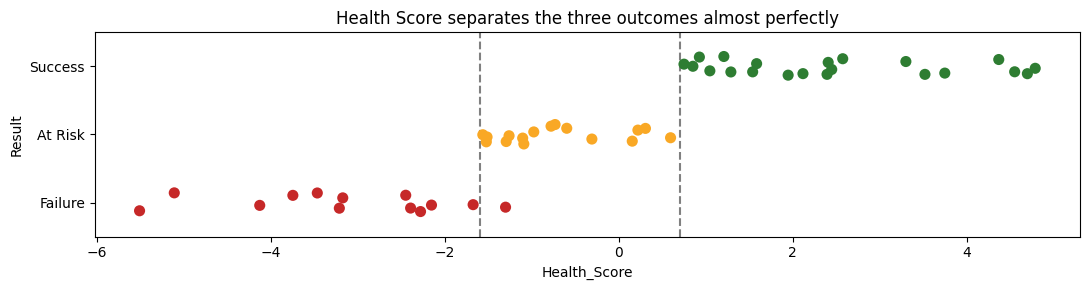

In [7]:
fig, ax = plt.subplots(figsize=(11, 3))
sns.stripplot(data=train_df, x="Health_Score", y="Result", order=ORDER, hue="Result",
              palette=PALETTE, legend=False, size=8, jitter=0.15, ax=ax)
ax.axvline(-1.6, ls="--", c="grey"); ax.axvline(0.7, ls="--", c="grey")
ax.set_title("Health Score separates the three outcomes almost perfectly")
plt.tight_layout(); plt.show()

### 3.3 Choosing the Thresholds
Set each threshold in the gap:
- **Failure** if score < **−1.6**.
- **Success** if score ≥ **0.7**.
- **At Risk** otherwise.

In [8]:
FAIL_T, SUCC_T = -1.6, 0.7

def classify(score):
    if score < FAIL_T:
        return "Failure"
    if score >= SUCC_T:
        return "Success"
    return "At Risk"

train_df["HS_Pred"] = train_df["Health_Score"].apply(classify)
print(f"Training accuracy: {accuracy_score(train_df['Result'], train_df['HS_Pred']):.0%}")
display(pd.DataFrame(confusion_matrix(train_df["Result"], train_df["HS_Pred"], labels=ORDER),
                     index=[f"true {c}" for c in ORDER], columns=[f"pred {c}" for c in ORDER]))
train_df.loc[train_df["Result"] != train_df["HS_Pred"], ["Flight ID", "Health_Score", "Result", "HS_Pred"]]

Training accuracy: 98%


,pred Success,pred At Risk,pred Failure
true Success,21,0,0
true At Risk,0,16,0
true Failure,0,1,12


,Flight ID,Health_Score,Result,HS_Pred
16,R-17,-1.302157,Failure,At Risk


The Health Score classifies 49 of 50 training flights correctly **(98%)**.

The only miss is **R-17**, a Failure predicted as At Risk, with a score of −1.30 that sits close to the failure threshold.

# 4. Model Evaluation

### 4.1 cross-validation: Comparing Two Models

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X, y = train_df[cols], train_df["Result"]

hs_scores = []
for tr_idx, te_idx in cv.split(X, y):
    tr, te = train_df.iloc[tr_idx], train_df.iloc[te_idx]
    pred = health_points(te, tr).sum(axis=1).apply(classify)
    hs_scores.append(accuracy_score(te["Result"], pred))

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=10, max_iter=2000)),
}
results = {"Health Score (ours)": hs_scores}
for name, m in models.items():
    results[name] = cross_val_score(m, X, y, cv=cv)

comparison = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in results.items()},
                          index=["CV accuracy (mean)", "std"]).T.round(2)
comparison

,CV accuracy (mean),std
Health Score (ours),0.92,0.07
Logistic Regression,0.88,0.10


the Health Score reached **92%** average accuracy, compared with **88%** for Logistic Regression. Its smaller standard deviation (0.07 vs 0.10) means its results were more stable across the 5 rounds.

explainable score performed as well as a machine-learning model

### 4.2 Sanity Check: Logistic Regression


In [10]:
lr = models["Logistic Regression"].fit(X, y)
coef = pd.DataFrame(lr[-1].coef_, index=lr[-1].classes_, columns=cols).T.round(2)
coef[["Success", "Failure"]]

,Success,Failure
Engine Temp (°C),-2.32,2.41
Speed (km/h),2.15,-2.37
Altitude (km),2.50,-2.17
Pressure (kPa),2.48,-2.60
Fuel Remaining (%),3.24,-2.95
Trajectory Deviation (°),-2.89,3.09


Logistic Regression learned its own weights from the data. All six weights came out **similar in size** (about 2.2 to 3.2), which supports the choice to give every reading an equal weight.

high engine temperature and trajectory deviation push towards Failure, while high speed, altitude, pressure and fuel push towards Success.

# 5. Challenge Predictions

### 5.1 Predicting the challenge flights

In [11]:
test_pts = health_points(test_df, train_df)
test_df["Health_Score"] = test_pts.sum(axis=1)
test_df["Prediction"] = test_df["Health_Score"].apply(classify)
test_df["LogReg_Check"] = lr.predict(test_df[cols])

agree = (test_df["Prediction"] == test_df["LogReg_Check"]).mean()
print(f"Agreement with Logistic Regression: {agree:.0%}")

Agreement with Logistic Regression: 100%


Logistic Regression was retrained on all 50 flights and agreed with the Health Score on all 15 challenge flights **(100%)**. Two different methods reaching the same predictions gives us more confidence in the results.

### 5.2 Extracting the main factors and reasoning
The top 2 factors come from the same score, so reasoning always matches the prediction.

In [12]:
units = {"Engine Temp (°C)": "°C", "Speed (km/h)": "km/h", "Altitude (km)": "km",
         "Pressure (kPa)": "kPa", "Fuel Remaining (%)": "%", "Trajectory Deviation (°)": "°"}

def describe(col, value, pts):
    good = pts > 0
    if col == "Engine Temp (°C)":
        adj = "low" if good else "high"
    elif col == "Trajectory Deviation (°)":
        adj = "small" if good else "large"
    else:
        adj = "high" if good else "low"
    return f"{adj} {short[col].lower()} ({value:g} {units[col]})"

f1, f2, reasons = [], [], []
for i, row in test_df.iterrows():
    pts = test_pts.loc[i].sort_values(ascending=(row["Prediction"] != "Success"))
    a, b = pts.index[0], pts.index[1]
    da, db = describe(a, row[a], pts[a]), describe(b, row[b], pts[b])
    s = row["Health_Score"]
    if row["Prediction"] == "Success":
        txt = f"Health score {s:+.2f} (≥ +0.70): {da} and {db} outweigh the weaker readings."
    elif row["Prediction"] == "Failure":
        txt = f"Health score {s:+.2f} (< −1.60): {da} and {db} push the flight into the failure zone."
    else:
        txt = f"Health score {s:+.2f} (between −1.60 and +0.70): {da} and {db} keep it out of the safe zone."
    if abs(s - SUCC_T) < 0.1 or abs(s - FAIL_T) < 0.1:
        txt += " Borderline case, so confidence is lower."
    f1.append(short[a]); f2.append(short[b]); reasons.append(txt)

test_df["Main Factor 1"], test_df["Main Factor 2"], test_df["Short Reasoning"] = f1, f2, reasons

# 6. Final Output

### 6.1 Create Submission File

In [13]:
submission = test_df[["Flight ID", "Prediction", "Main Factor 1", "Main Factor 2", "Short Reasoning"]]
pd.set_option("display.max_colwidth", None)
display(submission)
print(submission["Prediction"].value_counts())

,Flight ID,Prediction,Main Factor 1,Main Factor 2,Short Reasoning
0,R-51,Success,Altitude,Trajectory Deviation,Health score +1.47 (≥ +0.70): high altitude (29.5 km) and small trajectory deviation (1 °) outweigh the weaker readings.
1,R-52,Success,Pressure,Engine Temp,Health score +1.45 (≥ +0.70): high pressure (102.9 kPa) and low engine temp (630.6 °C) outweigh the weaker readings.
2,R-53,Failure,Fuel Remaining,Speed,Health score -5.27 (< −1.60): low fuel remaining (28.3 %) and low speed (579 km/h) push the flight into the failure zone.
3,R-54,Failure,Engine Temp,Altitude,Health score -6.05 (< −1.60): high engine temp (918.7 °C) and low altitude (9.2 km) push the flight into the failure zone.
4,R-55,Failure,Speed,Altitude,Health score -5.63 (< −1.60): low speed (509.2 km/h) and low altitude (9 km) push the flight into the failure zone.
5,R-56,At Risk,Fuel Remaining,Trajectory Deviation,"Health score +0.68 (between −1.60 and +0.70): low fuel remaining (31.5 %) and large trajectory deviation (4.9 °) keep it out of the safe zone. Borderline case, so confidence is lower."
6,R-57,Success,Trajectory Deviation,Fuel Remaining,Health score +2.25 (≥ +0.70): small trajectory deviation (0.7 °) and high fuel remaining (78.3 %) outweigh the weaker readings.
7,R-58,Success,Engine Temp,Altitude,Health score +1.89 (≥ +0.70): low engine temp (593.3 °C) and high altitude (28.3 km) outweigh the weaker readings.
8,R-59,Success,Engine Temp,Speed,Health score +1.00 (≥ +0.70): low engine temp (609 °C) and high speed (948.2 km/h) outweigh the weaker readings.
9,R-60,Failure,Fuel Remaining,Speed,Health score -2.51 (< −1.60): low fuel remaining (34.1 %) and low speed (631.1 km/h) push the flight into the failure zone.


Prediction
Success    8
Failure    4
At Risk    3
Name: count, dtype: int64


In [14]:
output_filename = "Smart_Rocket_Submission.xlsx"
submission.to_excel(output_filename, index=False)
print(f"✅ Predictions saved to '{output_filename}'")

✅ Predictions saved to 'Smart_Rocket_Submission.xlsx'


# 7. Summary
**Tools:**
- **pandas**: loading and preparing the data
- **matplotlib & seaborn**: visualizations
- **scikit-learn**: cross-validation and the Logistic Regression comparison model


**Method:**
1. Explored the 6 readings: all showed a clear pattern across outcomes.
2. Built a **Flight Health Score**: z-score each reading, apply its direction, sum.
3. Decision rule: Failure < −1.6 ≤ At Risk < 0.7 ≤ Success.
4. Validated with 5-fold cross-validation against Logistic Regression.

**Results:**
- **92%** accuracy on unseen flights (vs 88% for Logistic Regression).
- Predictions: **8 Success · 3 At Risk · 4 Failure**, each with its top 2 factors.